# Pergunta da pesquisa e público alvo

## Pergunta de Pesquisa  

![example_image](https://uk.yunextraffic.com/wp-content/uploads/sites/3/2022/11/Traffic_Signal_Maintenance_f46be67b-1984-400d-ba6b-ddc529fc3458-770x514.jpg)  

Neste estudo de visualização de dados, analisamos o conjunto de dados *311 Complaint Data* referente ao período de **1º de janeiro de 2020 às 01:01 AM a 25 de fevereiro de 2025 às 09:58 AM**. Nossa pergunta de pesquisa busca **identificar quais são as áreas da cidade com maior incidência de falhas em sinais de trânsito e quais são os problemas mais recorrentes**.  

A motivação para essa investigação reside na necessidade de compreender padrões de mau funcionamento da sinalização, permitindo a implementação de medidas eficazes para melhorar a segurança no trânsito.  

A identificação das regiões com maior número de falhas em semáforos, bem como a análise dos tipos de problemas mais comuns, pode fornecer insights valiosos para a **formulação de políticas públicas e estratégias de intervenção**. A partir dessa análise, é possível **priorizar a manutenção e modernização dos sinais de trânsito**, **otimizar a resposta de equipes de reparo** e **reduzir o risco de acidentes decorrentes de problemas na sinalização no trânsito**.

## Público-Alvo  

Os principais beneficiados por essa análise são **órgãos governamentais**, como departamentos de transporte e infraestrutura urbana, responsáveis pela manutenção e operação dos sinais de trânsito. A identificação das áreas com maior incidência de falhas permite um planejamento mais eficiente para a manutenção preventiva e corretiva desses dispositivos.  

Além disso, **equipes de fiscalização de trânsito** podem utilizar esses dados para otimizar suas ações e garantir que problemas nos sinais não comprometam a segurança. **Empresas de transporte e logística** também se beneficiam ao poderem planejar melhor suas rotas, reduzindo atrasos e melhorando a eficiência operacional.  

Organizações da sociedade civil, como **associações de mobilidade urbana e segurança no trânsito**, podem utilizar essas informações para pressionar por melhorias na infraestrutura e defender políticas públicas mais eficazes.  

Por fim, a **população em geral, incluindo motoristas, ciclistas e pedestres**, é diretamente impactada por essa análise. Com sinais de trânsito mais confiáveis, espera-se uma **redução do risco de acidentes, melhora na fluidez do tráfego e maior segurança para todos os usuários das ruas e avenidas**.  

# Configuração do ambiente

## Importações

In [100]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.express as px

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

import warnings
warnings.filterwarnings('ignore')

In [101]:
original_df = pd.read_csv("./data/Traffic_Sigal_Condition.csv")
# original_df

## Ajuste dos dados

In [102]:

# Removendo colunas que não são necessárias
unused_colunms = [
    "Unique Key", # Desnecessário
    "Agency", # Coluna duplicada com Agency Name
    "Complaint Type", # Já que foi filtrado todos são Traffic Signal Condition
    "Location Type", # Coluna vazia
    "Cross Street 1", # Desnecessária
    "Cross Street 2", # Desnecessária
    "Landmark", # Coluna vazia
    "Facility Type", # Valoes são N/A
    "Due Date", # Coluna vazia
    "Resolution Description", # Desnecessário
    "Resolution Action Updated Date", # Desnecessário
    "BBL", # Coluna Praticamente Vazia,
    "Vehicle Type",
    "Taxi Company Borough", # Coluna vazia
    "Taxi Pick Up Location", # Coluna vazia
    "Bridge Highway Name", # Coluna vazia
    "Bridge Highway Direction", # Coluna vazia
    "Road Ramp", # Coluna vazia
    "Bridge Highway Segment", # Coluna vazia
]
df = original_df.drop(columns=unused_colunms)
# print("Colunas restantes:", len(df.columns))
display(df.head())

,Created Date,Closed Date,Agency Name,Descriptor,Incident Zip,Incident Address,Street Name,Intersection Street 1,Intersection Street 2,Address Type,City,Status,Community Board,Borough,X Coordinate (State Plane),Y Coordinate (State Plane),Open Data Channel Type,Park Facility Name,Park Borough,Latitude,Longitude,Location
0,02/24/2025 12:58:00 AM,NaN,Department of Transportation,Controller,11217.0,NaN,NaN,3 AVENUE,ATLANTIC AVENUE,INTERSECTION,BROOKLYN,Open,02 BROOKLYN,BROOKLYN,989602.0,188959.0,UNKNOWN,Unspecified,BROOKLYN,40.685324,-73.980703,"(40.685323956671624, -73.98070251676813)"
1,02/24/2025 12:35:00 AM,NaN,Department of Transportation,Pedestrian Signal,10033.0,NaN,NaN,AUDUBON AVENUE,WEST 186 STREET,INTERSECTION,MANHATTAN,Open,12 MANHATTAN,MANHATTAN,1003588.0,249617.0,UNKNOWN,Unspecified,MANHATTAN,40.851795,-73.930099,"(40.85179479152171, -73.93009926586655)"
2,02/24/2025 12:30:00 AM,NaN,Department of Transportation,Controller,10466.0,NaN,NaN,DE REIMER AVENUE,PITMAN AVENUE,INTERSECTION,BRONX,Open,12 BRONX,BRONX,1027332.0,266080.0,UNKNOWN,Unspecified,BRONX,40.896897,-73.844167,"(40.89689665685237, -73.84416650662719)"
3,02/23/2025 11:13:00 PM,NaN,Department of Transportation,Pedestrian Signal,11218.0,NaN,NaN,19 STREET,10 AVENUE,INTERSECTION,BROOKLYN,Open,07 BROOKLYN,BROOKLYN,989460.0,178212.0,UNKNOWN,Unspecified,BROOKLYN,40.655826,-73.981223,"(40.6558259311886, -73.98122282660836)"
4,02/23/2025 10:00:00 PM,02/24/2025 12:05:00 AM,Department of Transportation,Wireless,11233.0,NaN,NaN,SARATOGA AVENUE,FULTON STREET,INTERSECTION,BROOKLYN,Closed,03 BROOKLYN,BROOKLYN,1007466.0,186511.0,UNKNOWN,Unspecified,BROOKLYN,40.678576,-73.916299,"(40.678575927581726, -73.91629949498605)"


In [103]:
# Função para ajustar a localização real do incidente
def adjust_real_incident(df):
    def get_location(row):
        if row['Address Type'] == 'INTERSECTION':
            streets = [row['Intersection Street 1'], row['Intersection Street 2']]
            streets = sorted(filter(lambda x: pd.notna(x), streets))  # Remove NaN e ordena
            return ", ".join(streets)
        return row['Incident Address']
    
    df = df.copy()  # Evita modificar o original
    df['Real Incident Location'] = df.apply(get_location, axis=1)
    return df

def clean_descriptor(df):
    df = df.copy()
    df = df.dropna(subset=['Descriptor'])
    return df

def clean_borough(df):
    df = df.copy()
    df = df.dropna(subset=['Borough'])
    df['Borough'] = df['Borough'].str.title() # Capitalizar nome dos condados
    return df

# Isso já limpa também os dados faltantes em Longitude e Latitude
def clean_location(df):
    df = df.copy()
    df = df.dropna(subset=['Location'])
    df['Location'] = df['Location'].str.title() # Capitalizar nome dos condados
    return df

# Converter latitude para float
def clean_latitude(df):
    df["Latitude"] = pd.to_numeric(df["Latitude"], errors="coerce")
    return df

# Converter latitude para float
def clean_longitude(df):
    df["Longitude"] = pd.to_numeric(df["Longitude"], errors="coerce")
    return df

pipeline = Pipeline(steps=[
    ("adjust_real_incident", FunctionTransformer(adjust_real_incident)),
    ("clean_descriptor", FunctionTransformer(clean_descriptor)),
    ("clean_park_borough", FunctionTransformer(clean_borough)),
    ("clean_location", FunctionTransformer(clean_location)),
    ("clean_latitude", FunctionTransformer(clean_location)),
    ("clean_longitude", FunctionTransformer(clean_location)),
])

Aqui, fizemos um ajuste no pipeline para criar a coluna **`real_incident_location`**, garantindo que a localização do incidente seja corretamente atribuída com base no tipo de endereço disponível. Se o campo **`Address Type`** não for **"INTERSECTION"**, utilizamos diretamente o valor de **`Incident Address`**. Caso contrário, combinamos os valores de **`Intersection Street 1`** e **`Intersection Street 2`**, removemos possíveis valores ausentes, ordenamos lexicograficamente e os unimos com uma vírgula. Esse ajuste padroniza as informações de localização, facilitando análises futuras.

In [104]:
df = pipeline.fit_transform(df)
df.head()

,Created Date,Closed Date,Agency Name,Descriptor,Incident Zip,Incident Address,Street Name,Intersection Street 1,Intersection Street 2,Address Type,City,Status,Community Board,Borough,X Coordinate (State Plane),Y Coordinate (State Plane),Open Data Channel Type,Park Facility Name,Park Borough,Latitude,Longitude,Location,Real Incident Location
0,02/24/2025 12:58:00 AM,NaN,Department of Transportation,Controller,11217.0,NaN,NaN,3 AVENUE,ATLANTIC AVENUE,INTERSECTION,BROOKLYN,Open,02 BROOKLYN,Brooklyn,989602.0,188959.0,UNKNOWN,Unspecified,BROOKLYN,40.685324,-73.980703,"(40.685323956671624, -73.98070251676813)","3 AVENUE, ATLANTIC AVENUE"
1,02/24/2025 12:35:00 AM,NaN,Department of Transportation,Pedestrian Signal,10033.0,NaN,NaN,AUDUBON AVENUE,WEST 186 STREET,INTERSECTION,MANHATTAN,Open,12 MANHATTAN,Manhattan,1003588.0,249617.0,UNKNOWN,Unspecified,MANHATTAN,40.851795,-73.930099,"(40.85179479152171, -73.93009926586655)","AUDUBON AVENUE, WEST 186 STREET"
2,02/24/2025 12:30:00 AM,NaN,Department of Transportation,Controller,10466.0,NaN,NaN,DE REIMER AVENUE,PITMAN AVENUE,INTERSECTION,BRONX,Open,12 BRONX,Bronx,1027332.0,266080.0,UNKNOWN,Unspecified,BRONX,40.896897,-73.844167,"(40.89689665685237, -73.84416650662719)","DE REIMER AVENUE, PITMAN AVENUE"
3,02/23/2025 11:13:00 PM,NaN,Department of Transportation,Pedestrian Signal,11218.0,NaN,NaN,19 STREET,10 AVENUE,INTERSECTION,BROOKLYN,Open,07 BROOKLYN,Brooklyn,989460.0,178212.0,UNKNOWN,Unspecified,BROOKLYN,40.655826,-73.981223,"(40.6558259311886, -73.98122282660836)","10 AVENUE, 19 STREET"
4,02/23/2025 10:00:00 PM,02/24/2025 12:05:00 AM,Department of Transportation,Wireless,11233.0,NaN,NaN,SARATOGA AVENUE,FULTON STREET,INTERSECTION,BROOKLYN,Closed,03 BROOKLYN,Brooklyn,1007466.0,186511.0,UNKNOWN,Unspecified,BROOKLYN,40.678576,-73.916299,"(40.678575927581726, -73.91629949498605)","FULTON STREET, SARATOGA AVENUE"


# Visualizações

### Visualização 1 - Gráfico de barras da quantidade de incidentes por condado de Nova York

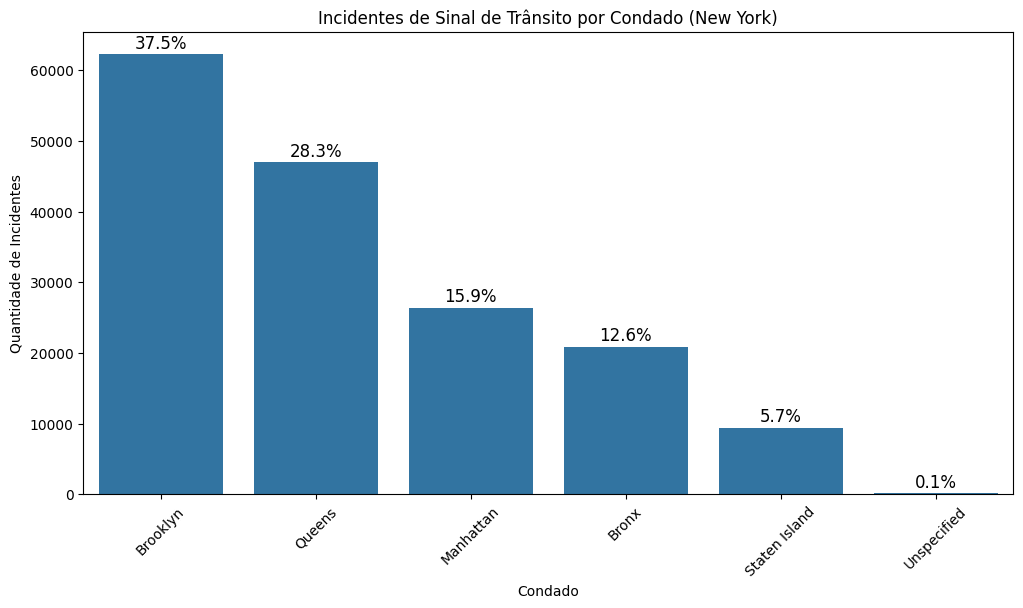

In [105]:
# Contar os incidentes por condado
borough_counts = df['Borough'].value_counts().nlargest(10).reset_index()
borough_counts.columns = ['Borough', 'Count']

# Calcular o total de incidentes
total_incidents = borough_counts['Count'].sum()

# Criar o gráfico de barras
plt.figure(figsize=(12, 6))
ax = sns.barplot(data=borough_counts, x='Borough', y='Count', dodge=True)

# Adicionar porcentages
for p in ax.patches:
    percentage = (p.get_height() / total_incidents) * 100
    ax.annotate(f'{percentage:.1f}%', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                fontsize=12, color='black', 
                xytext=(0, 8), textcoords='offset points')

plt.xticks(rotation=45)
plt.xlabel("Condado")
plt.ylabel("Quantidade de Incidentes")
plt.title("Incidentes de Sinal de Trânsito por Condado (New York)")
plt.show()

#### Explicação dos dados encontrados

Os dados mostram que **Brooklyn e Queens** concentram a maior parte dos incidentes de sinal de trânsito em Nova York, **representando juntos 63,6% do total**. Brooklyn, sozinho, responde por 35,4% dos casos, enquanto Queens representa 28,2%. Isso significa que mais da **metade dos incidentes ocorrem nesses dois condados**. 

Manhattan aparece em terceiro lugar, com 17% dos incidentes, seguido pelo Bronx, que tem 13,7%. **Staten Island registra apenas 5%, sendo o condado com a menor quantidade de ocorrências**. Além disso, 0,7% dos incidentes não tiveram um local especificado.  

Esses números indicam que a distribuição dos incidentes está fortemente concentrada nos condados mais populosos e com maior fluxo de veículos. Assim, **medidas como melhoria na sinalização, fiscalização mais rigorosa e campanhas educativas podem ajudar a reduzir esses números**, especialmente em Brooklyn e Queens, onde os incidentes são mais frequentes.

#### Explicação do desing escolhido

Optei por um **gráfico de barras** porque ele é ideal para comparar quantidades categóricas distintas. Neste caso, os condados representam categorias, e a contagem de incidentes em cada um é exibida claramente em colunas verticais. Algumas razões para essa escolha incluem:

- **Comparação clara e direta**: Cada condado é representado por uma barra, facilitando a visualização dos condados com maior e menor número de incidentes.  
- **Legibilidade**: Os rótulos no eixo X permitem identificar rapidamente os condados, e a escala no eixo Y dá uma noção da proporção de incidentes entre eles.  
- **Análise percentual**: Além da contagem bruta, adicionei **percentuais acima das barras**, para indicar a participação relativa de cada condado no total de incidentes. Isso ajuda a compreender melhor a distribuição dos eventos.  

### Visualização 2 - Mapa de calor de incidentes com sinais de trânsito em New York

In [106]:
# Agrupamentos dos dados para heatmap
heatmap_data = df.groupby(["Latitude", "Longitude"]).size().reset_index(name="Incidents")

# Criando mapa de calor com Plotly
fig = px.density_map(
    heatmap_data,
    lat="Latitude",
    lon="Longitude",
    z="Incidents",
    radius=10,  # Ajuste para suavizar ou concentrar o calor
    center={"lat": 40.7, "lon": -74.0},
    zoom=9,
    map_style="carto-positron",
    color_continuous_scale="YlOrRd"
)

fig.update_layout(title="Mapa de Calor de Incidentes de Com Sinais de Trânsito em Nova York")
fig.show()

#### Explicação dos dados encontrados

O mapa de calor evidencia que Brooklyn, Queens e Manhattan são as regiões com maior concentração de incidentes relacionados a sinais de trânsito em Nova York. **As áreas mais escuras nesses condados indicam uma alta densidade de ocorrências, especialmente em pontos estratégicos com grande fluxo de veículos e pedestres**. Esse padrão reforça os dados anteriores, que mostravam que Brooklyn e Queens, juntos, representam mais de 60% dos incidentes registrados. Um exemplo notável é a **Interstate 278 (I-278), uma rodovia que corta Brooklyn e Queens e é conhecida por seu alto volume de tráfego e frequentes problemas relacionados à sinalização de trânsito**.

#### Explicação do desing escolhido

Optei por um **mapa de calor** porque ele é ideal para visualizar **concentrações espaciais de eventos**. Algumas razões para essa escolha incluem:

- **Identificação de padrões espaciais**: O mapa permite ver rapidamente quais áreas têm maior densidade de incidentes, facilitando a tomada de decisões para fiscalização e manutenção.  
- **Representação intuitiva**: Áreas com **mais incidentes aparecem em tons mais quentes (vermelho, laranja, amarelo)**, enquanto áreas com menos problemas aparecem em cores mais frias. Essa escala de cores facilita a leitura e interpretação do gráfico.  
- **Interatividade**: O uso do **Plotly** permite que o usuário explore o mapa interativamente, dando zoom e passando o mouse para inspecionar áreas específicas. Isso torna a análise muito mais rica do que um gráfico estático.  

### Visualização 3 - Histograma incidentes por localização (Brooklyn e Queens)

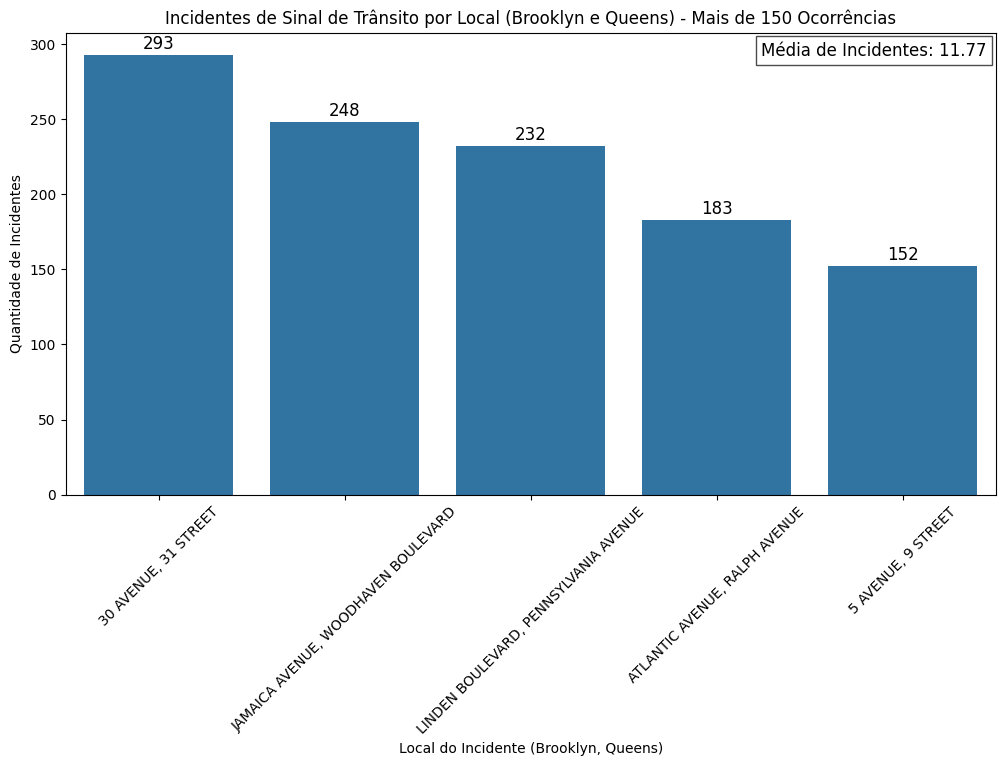

In [107]:
import matplotlib.pyplot as plt
import seaborn as sns

# Filtrar por Brooklyn e Queens
df_filtered = df[df['Borough'].isin(['Brooklyn', 'Queens'])]

# Contar os incidentes por "Real Incident Location"
location_counts = df_filtered['Real Incident Location'].value_counts().reset_index()
location_counts.columns = ['Real Incident Location', 'Count']

# Filtrar para incluir apenas locais com mais de 150 ocorrências
location_counts_filtered_150 = location_counts[location_counts['Count'] > 150]

# Calcular a média de incidentes em todos os locais
average_incidents = location_counts['Count'].mean()

# Criar gráfico de barras
plt.figure(figsize=(12, 6))
ax = sns.barplot(data=location_counts_filtered_150, x='Real Incident Location', y='Count', dodge=True)

# Quantidade exata no top das barras
for p in ax.patches:
    count = int(p.get_height())
    ax.annotate(f'{count}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                fontsize=12, color='black', 
                xytext=(0, 8), textcoords='offset points')

# Legenda com média dos incidentes
plt.text(0.748, 0.95, f'Média de Incidentes: {average_incidents:.2f}', 
         transform=plt.gca().transAxes, fontsize=12, 
         bbox=dict(facecolor='white', alpha=0.7, edgecolor='black'))
plt.xticks(rotation=45)
plt.xlabel("Local do Incidente (Brooklyn, Queens)")
plt.ylabel("Quantidade de Incidentes")
plt.title("Incidentes de Sinal de Trânsito por Local (Brooklyn e Queens) - Mais de 150 Ocorrências")
plt.show()


#### Explicação dos dados encontrados

Este gráfico de barras representa os locais em Brooklyn e Queens com maior reincidência de incidentes relacionados a sinais de trânsito. Todos os **pontos destacados são cruzamentos, o que faz sentido, pois esses locais naturalmente apresentam maior fluxo de veículos e pedestres, aumentando a probabilidade de incidentes.**

A motivação para criar esse gráfico foi identificar os pontos mais críticos em relação a esse tipo de problema. **Filtramos os dados para exibir apenas os locais com mais de 150 ocorrências**, revelando cinco cruzamentos com um número significativamente alto de incidentes.

Outro ponto relevante é que os valores apresentados no gráfico estão muito acima da média geral de incidentes por local, que é de apenas **11.77**. **Isso indica que esses cruzamentos possuem um problema muito mais grave do que a maioria dos outros locais, tornando-os alvos prioritários para possíveis intervenções e melhorias na sinalização e infraestrutura viária**.

#### Explicação do desing escolhido

- Escolha do gráfico de barras
  - Comparar diretamente a quantidade de incidentes em cada local.
  - Diferenciar facilmente os cruzamentos com mais ocorrências.
  - Anotar valores nas barras, destacando a magnitude de cada ponto.

##### Decisões de Filtro e Legendas

1. Filtragem para locais com **mais de 150 incidentes**
   - Esse critério foi escolhido para focar apenas nos pontos mais críticos e evitar que locais com poucas ocorrências dificultassem a identificação de padrões.
   - Se todos os locais fossem incluídos, o gráfico ficaria desorganizado e difícil de interpretar.
2. Adição de uma **média de incidentes no gráfico**
   - Incluir a média de incidentes ajuda a contextualizar os dados e responder se um local tem significativamente mais incidentes do que a maioria dos outros.
3. Anotações nas barras
   - Adicionar os **números exatos de incidentes** no topo de cada barra melhora a interpretação, permitindo uma **leitura rápida dos valores**.
   

### Visualização 4 - Gráficos de setores com os problemas mais recorrentes nos 5 cruzamentos (mais de 5 ocorrências)

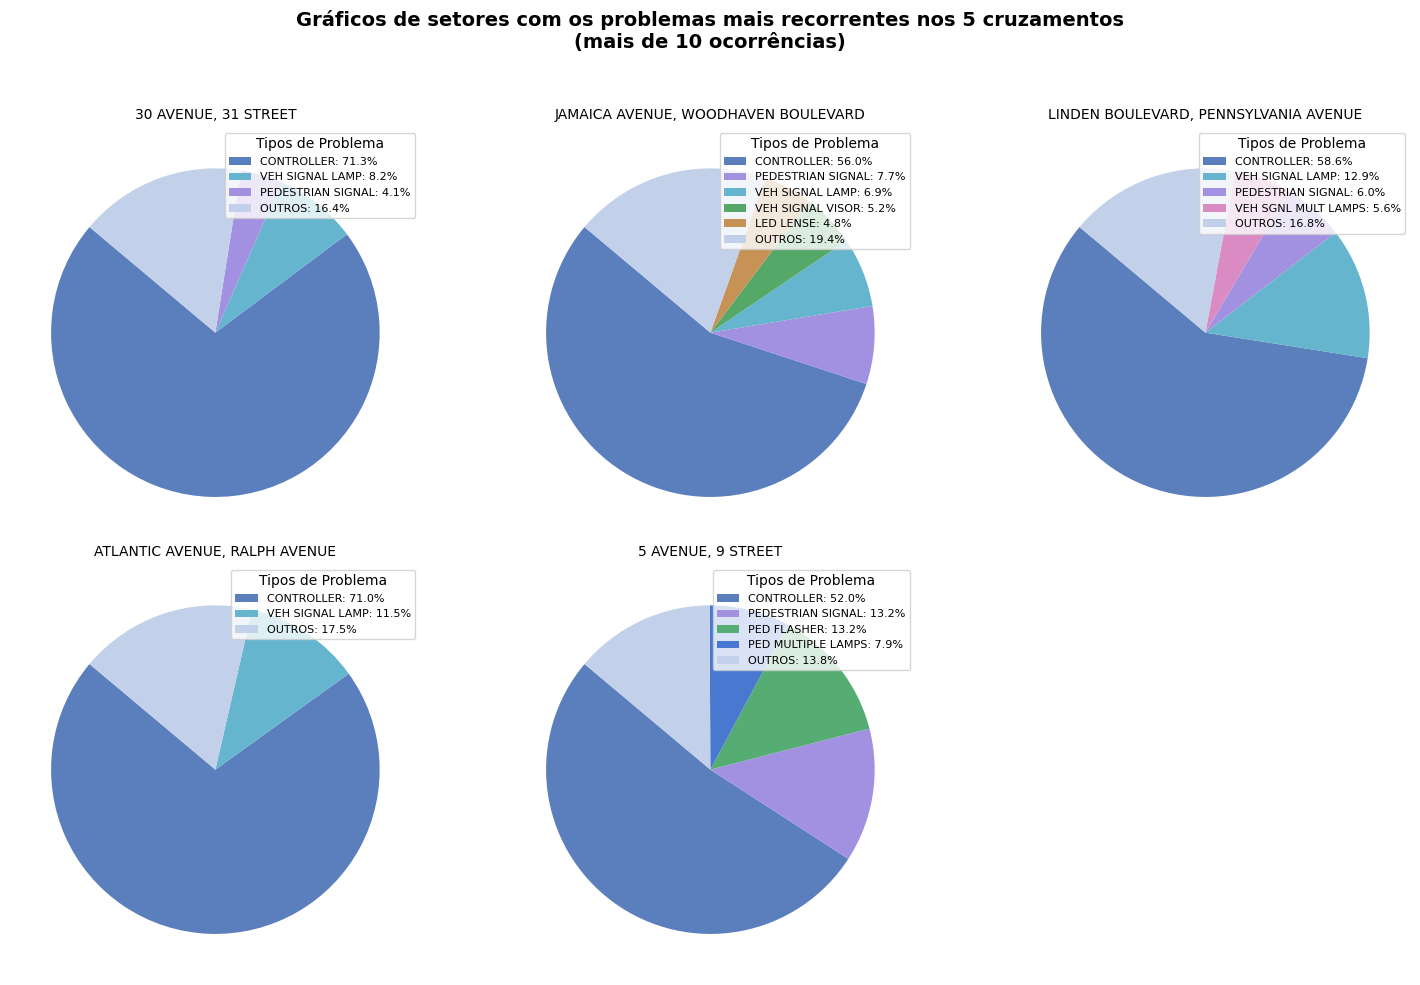

In [108]:
import matplotlib.pyplot as plt
import seaborn as sns

top_locations = [
    "30 AVENUE, 31 STREET",
    "JAMAICA AVENUE, WOODHAVEN BOULEVARD",
    "LINDEN BOULEVARD, PENNSYLVANIA AVENUE",
    "ATLANTIC AVENUE, RALPH AVENUE",
    "5 AVENUE, 9 STREET"
]

# [ Normalização de cores ]
unique_problems = set()

for location in top_locations:
    df_location = df_filtered[df_filtered['Real Incident Location'].str.upper().str.strip() == location]
    unique_problems.update(df_location['Descriptor'].str.upper().str.strip().unique())

palette = sns.color_palette("deep", n_colors=len(unique_problems) + 1)  # +1 para "OUTROS"

colors_map = {problem: palette[i] for i, problem in enumerate(unique_problems)}
#Ajustando cores que ficaram feias
colors_map["OUTROS"] = "#c2d0e9"  
colors_map["CONTROLLER"] = "#5b7ebd"  
colors_map["PEDESTRIAN SIGNAL"] = "#a291e1"  
colors_map["PED FLASHER"] = "#56ad74"  
colors_map["PED MULTIPLE LAMPS"] = "#4878d0"  
colors_map["LED LENSE"] = "#c69255"  

# Utilizar subplot para mostrar os 5 gráficos
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Adicionar um título geral para o gráfico
fig.suptitle("Gráficos de setores com os problemas mais recorrentes nos 5 cruzamentos\n(mais de 10 ocorrências)", 
             fontsize=14, fontweight="bold")

axes = axes.flatten()

for i, location in enumerate(top_locations):
    # Filtrar os incidentes do local
    df_location = df_filtered[df_filtered['Real Incident Location'].str.upper().str.strip() == location]

    # Contar os tipos de problemas
    df_location['Descriptor'] = df_location['Descriptor'].str.upper().str.strip()
    problem_counts = df_location['Descriptor'].value_counts()
    
    # Separar os problemas em recorrentes e "Outros"
    frequent_problems = problem_counts[problem_counts > 10]
    infrequent_problems = problem_counts[problem_counts <= 10]
    
    # Somar os problemas menos frequentes
    if not infrequent_problems.empty:
        frequent_problems["OUTROS"] = infrequent_problems.sum()
    
    # Definir cores para os problemas do gráfico atual
    colors = [colors_map[problem] for problem in frequent_problems.index]

    # Criar o gráfico de seções
    wedges, texts = axes[i].pie(frequent_problems, labels=None, startangle=140, colors=colors)
    
    # Criar legenda com as porcentagens
    legend_labels = [f"{label}: {perc:.1f}%" for label, perc in 
                     zip(frequent_problems.index, (frequent_problems / frequent_problems.sum()) * 100)]
    axes[i].legend(wedges, legend_labels, title="Tipos de Problema", loc="upper right", fontsize=8)
    axes[i].set_title(location, fontsize=10)

# Remover subplot vazio (último espaço na grade 2x3)
fig.delaxes(axes[-1])

# Ajustar layout
plt.tight_layout(rect=[0, 0, 1, 0.95])  # Ajustar para não sobrepor o título
plt.show()

#### Explicação dos dados encontrados

O gráfico exibe a distribuição dos principais tipos de problemas em cinco cruzamentos de **Brooklyn e Queens** com alto número de incidentes de sinais de trânsito. Cada gráfico de pizza representa um cruzamento, e as cores indicam diferentes tipos de problemas detectados.  

##### **O principal problema: "Controller"**  

Podemos observar que o problema mais frequente nesses cruzamentos está relacionado ao **"Controller"**, que corresponde a falhas no controlador do semáforo. O **controlador** é o equipamento eletrônico responsável por gerenciar o funcionamento dos sinais de trânsito, determinando a ordem e o tempo das luzes (verde, amarelo e vermelho). Quando há falhas, isso pode causar problemas como:  

- **Semáforos apagados ou piscando**, aumentando o risco de acidentes.  
- **Mudanças de sinal irregulares**, levando a congestionamentos.  
- **Falta de sincronização entre semáforos**, dificultando o fluxo do trânsito.  

**61.38% dos problemas nesses cruzamentos estão relacionados a falhas no controlador do semáforo**, mostrando que esse é um grande desafio para a manutenção do trânsito nessas áreas. 

#### Explicação do desing escolhido

Optamos por gráficos de setores (gráficos de pizza) para representar a distribuição dos tipos de problemas nos cinco cruzamentos com mais incidentes. Esse tipo de visualização é **ideal para mostrar a proporção de cada categoria dentro de um conjunto de dados**, permitindo uma rápida compreensão das ocorrências mais frequentes em cada local. A ideia foi **facilitar a análise comparativa entre diferentes cruzamentos e identificar padrões de problemas que ocorrem com maior frequência**.

- Estrutura e Layout
   - Organizamos os gráficos em uma grade 2x3 para facilitar a comparação visual.  
   - O título principal fornece contexto sobre o que os gráficos representam.  
   - Legendas foram adicionadas no canto superior direito de cada gráfico para identificar claramente os problemas representados e sua porcentagens.  
- Normalização das cores:
    - Para evitar confusão na interpretação, estabelecemos um esquema de cores fixo para cada tipo de problema. Isso garante que um mesmo problema tenha sempre a mesma cor em todos os gráficos, permitindo comparações precisas entre cruzamentos.
- Filtragem de dados
   - Apenas problemas com mais de 10 ocorrências foram destacados, garantindo que os gráficos fossem legíveis e focados nas categorias mais relevantes.

# Conclusões

A análise conjunta das visualizações revelou que Brooklyn e Queens são os condados com maior incidência de problemas relacionados a sinais de trânsito, concentrando mais de 60% dos incidentes. Além disso, os cruzamentos nessas regiões apresentam um número muito superior à média geral, com problemas recorrentes ligados ao controlador de semáforos, que representa **61,38% das falhas identificadas**. Essa predominância de falhas no equipamento de controle sinaliza um problema estrutural significativo, impactando tanto a segurança dos pedestres quanto o fluxo do trânsito. A distribuição geográfica dos incidentes e os pontos críticos identificados reforçam a necessidade de uma ação prioritária nesses locais, visando a redução de riscos e a melhoria da mobilidade urbana.  

Com base nessas conclusões, recomenda-se que órgãos responsáveis, como o **Departamento de Transportes da Cidade de Nova York (NYC DOT)**, priorizem a manutenção preventiva e a modernização dos controladores de semáforos nos pontos mais afetados. Além disso, aumentar a fiscalização nesses cruzamentos críticos e investir em **soluções tecnológicas, como sensores inteligentes e sistemas de controle remoto**, poderia reduzir significativamente os problemas e otimizar o fluxo do trânsito. Campanhas de conscientização para motoristas e pedestres também podem contribuir para minimizar incidentes, enquanto um monitoramento contínuo dos dados ajudaria a identificar padrões emergentes e ajustar estratégias conforme necessário.